Loading Native Julia AC-Capable Surrogates... (This only happens once)
Successfully loaded Native Julia LUTs!

 TRANSIENT BATCH EVALUATION: 300 CIRCUITS (MILLER OTA BUFFER)
Compiled Custom DC, AC, and Transient Simulator Successfully!

>>> Running 300-Batch Transient Solves on 20 Julia Threads (Adaptive Time Steps)...
Julia 300-Circuit Transient Total Time: 3.843 s
    Saved fresh Julia results to: C:\Users\mohamed\Desktop\ML\CAD_projects\Netlists\GF_180nm_tech_work\project\New_Sim_tests\Allah_help_me2\Allah_Save_me\New folder\system\Testing\Spice_vs_Julia_Benchmarking\julia_miller_buffer_cache_300.jld2

>>> Running LTspice baseline (Sequential)...
    LTspice progress: 30/300 circuits done...
    LTspice progress: 60/300 circuits done...
    LTspice progress: 90/300 circuits done...
    LTspice progress: 120/300 circuits done...
    LTspice progress: 150/300 circuits done...
    LTspice progress: 180/300 circuits done...
    LTspice progress: 210/300 circuits done...
    LTspice progr

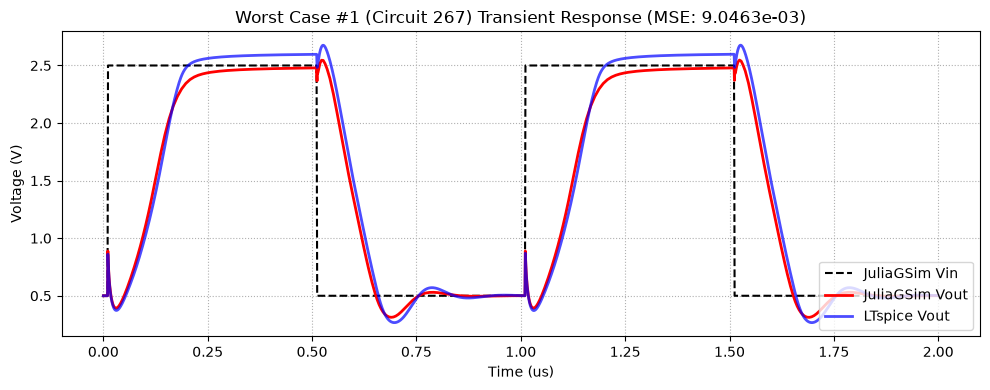


----------------------------------------------------------------------
Worst Case #2 (Circuit 246) - MSE: 9.0112e-03, SR Diff: 1.47 V/us
Params: M=27.0, L=8.7um, MB=13.0
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 16.51       V/us | 17.98       V/us
Difference      | 1.47        V/us |



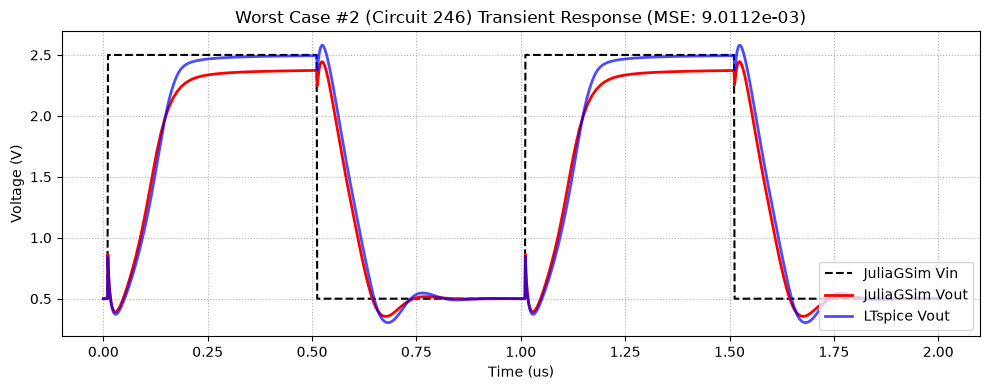


----------------------------------------------------------------------
Worst Case #3 (Circuit 287) - MSE: 8.7502e-03, SR Diff: 3.21 V/us
Params: M=29.0, L=10.0um, MB=14.0
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 13.69       V/us | 16.90       V/us
Difference      | 3.21        V/us |



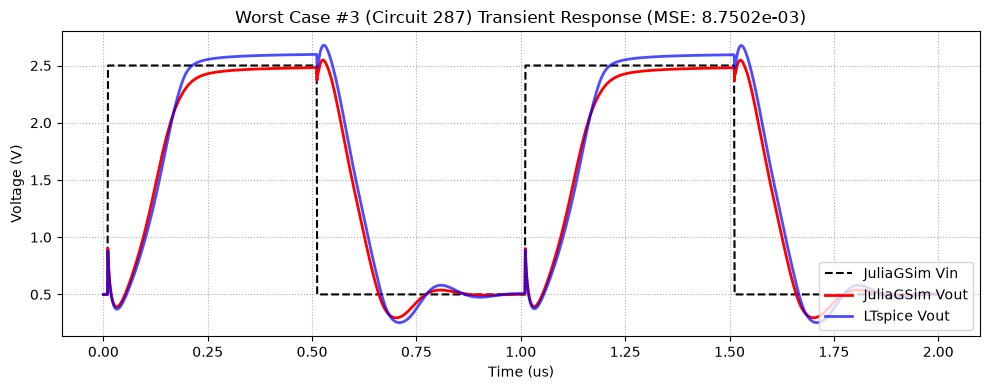


----------------------------------------------------------------------
Worst Case #4 (Circuit 245) - MSE: 8.6958e-03, SR Diff: 0.17 V/us
Params: M=26.0, L=8.7um, MB=13.0
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 17.26       V/us | 17.42       V/us
Difference      | 0.17        V/us |



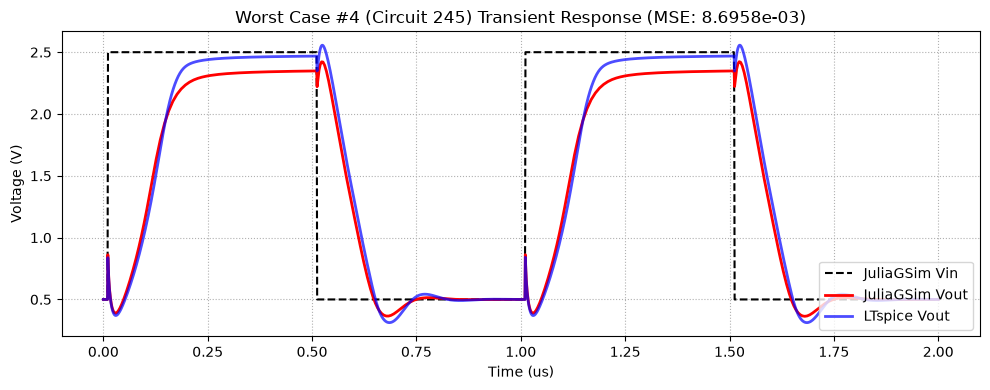


----------------------------------------------------------------------
Worst Case #5 (Circuit 226) - MSE: 8.3680e-03, SR Diff: 1.21 V/us
Params: M=27.0, L=8.1um, MB=13.0
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 17.57       V/us | 18.78       V/us
Difference      | 1.21        V/us |



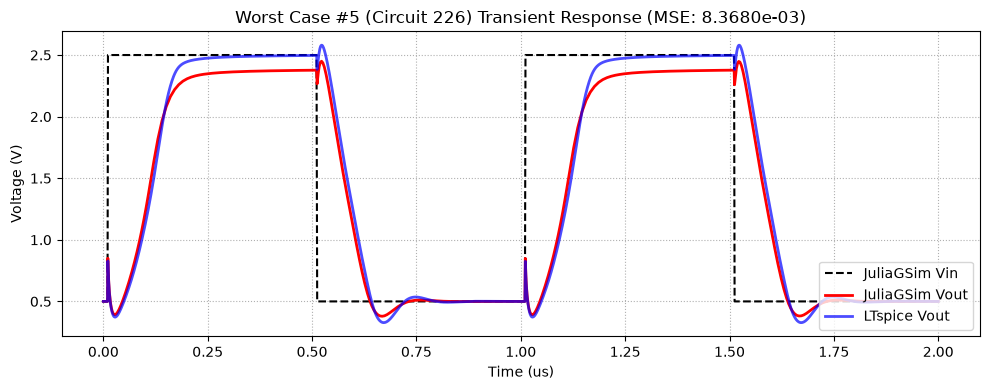


----------------------------------------------------------------------
Worst Case #6 (Circuit 225) - MSE: 8.2339e-03, SR Diff: 0.55 V/us
Params: M=26.0, L=8.1um, MB=13.0
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 17.67       V/us | 18.22       V/us
Difference      | 0.55        V/us |



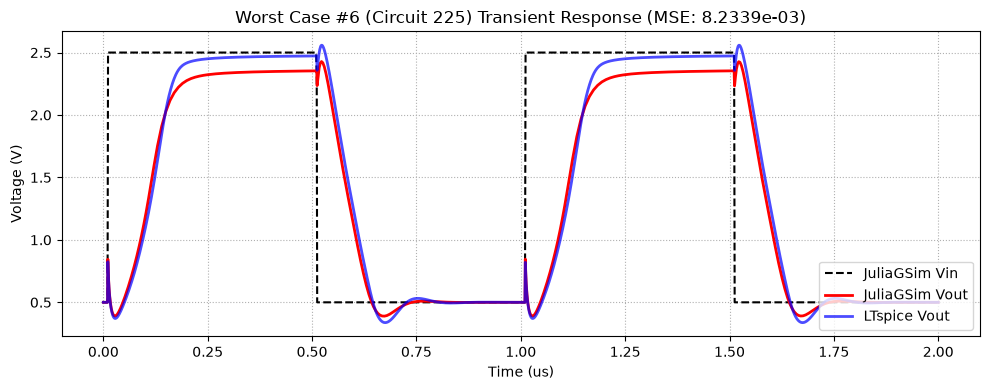


----------------------------------------------------------------------
Worst Case #7 (Circuit 288) - MSE: 8.1854e-03, SR Diff: 1.06 V/us
Params: M=31.0, L=10.0um, MB=15.0
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 16.15       V/us | 17.21       V/us
Difference      | 1.06        V/us |



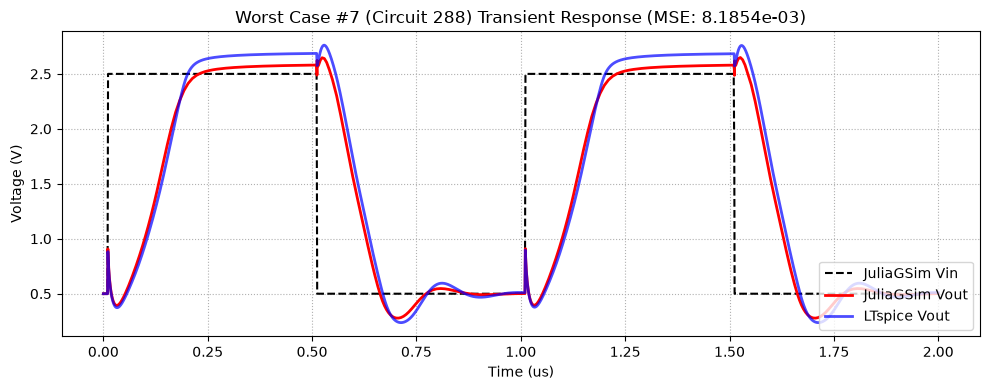


----------------------------------------------------------------------
Worst Case #8 (Circuit 266) - MSE: 8.0295e-03, SR Diff: 4.95 V/us
Params: M=27.0, L=9.4um, MB=13.0
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 12.21       V/us | 17.16       V/us
Difference      | 4.95        V/us |



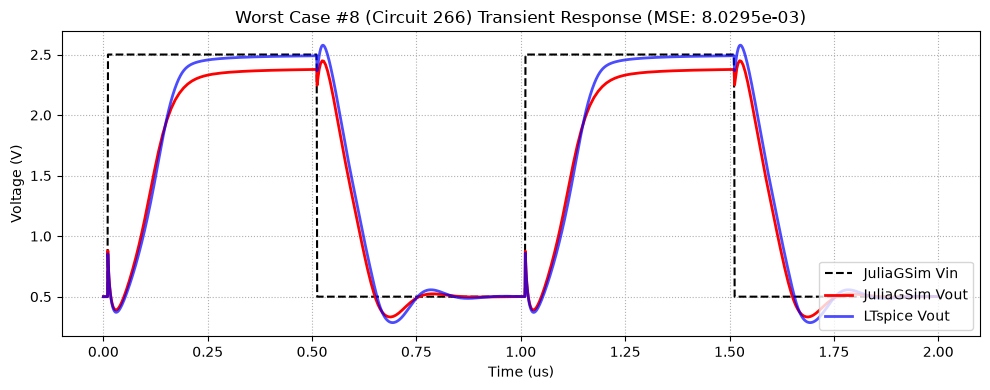


----------------------------------------------------------------------
Worst Case #9 (Circuit 265) - MSE: 7.6890e-03, SR Diff: 5.07 V/us
Params: M=26.0, L=9.4um, MB=13.0
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 11.55       V/us | 16.62       V/us
Difference      | 5.07        V/us |



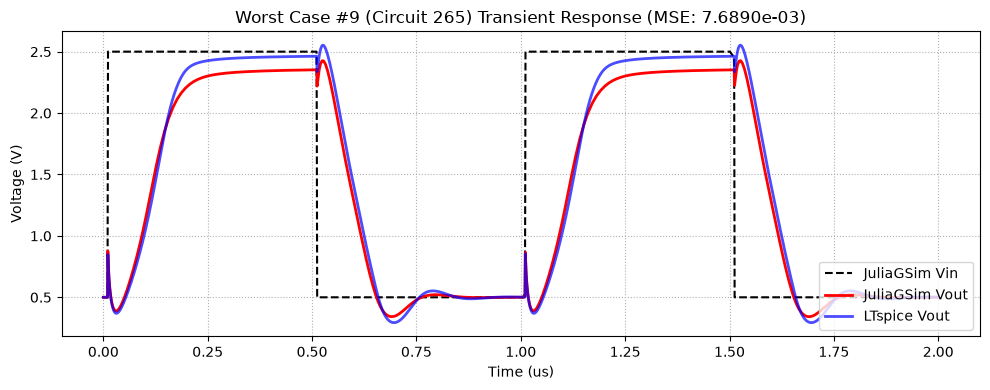


----------------------------------------------------------------------
Worst Case #10 (Circuit 247) - MSE: 7.6013e-03, SR Diff: 0.05 V/us
Params: M=29.0, L=8.7um, MB=14.0
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 18.24       V/us | 18.29       V/us
Difference      | 0.05        V/us |



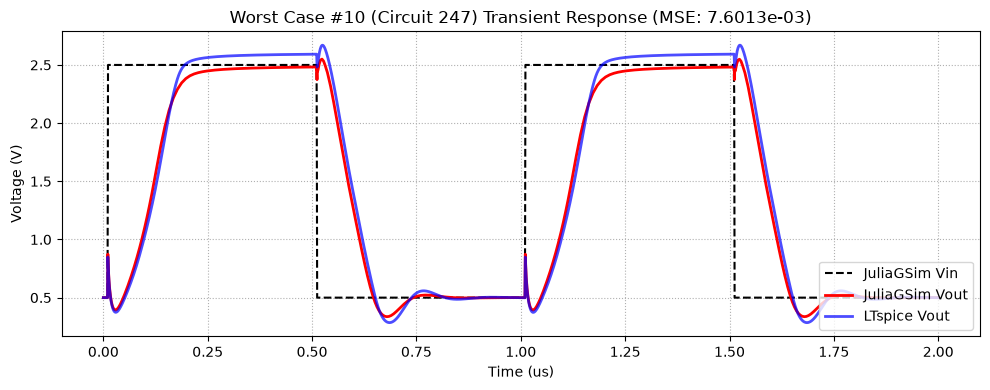

In [1]:
# 0. Set Python Environment
ENV["JULIA_PYTHONCALL_EXE"] = "C:\\Users\\mohamed\\.conda\\envs\\Thesis_Optimizer_Sandbox_Copy\\python.exe"

using Printf
using StaticArrays
using PythonCall
using Random
using JLD2
using Interpolations
using Statistics
using Base.Threads

# ==============================================================================
# 1. Call the Surrogate definitions and the simulator Engine
# ==============================================================================
# 1. Load technology model definitions
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Surrogate_definitions.jl")

# 2. Load the Engine (choose Static for small circuits or Sparse for large circuits)
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Static_Sim.jl")


# ==============================================================================
# 2. LTSPICE VERIFICATION GROUND TRUTH 
# ==============================================================================
g = pydict()
pyexec(raw"""
import os, subprocess, numpy as np
from PyLTSpice import RawRead

def run_ltspice_miller_tran(Ld, Lm, Lss, md, mm, mss, mb, m7, m6, Ib, Cc, Rz, CL, BASE_DIR='.'):
    os.makedirs(BASE_DIR, exist_ok=True)
    LTSPICE_PATH = r"C:\Users\Mohamed\AppData\Local\Programs\ADI\LTspice\LTspice.exe"
    
    netlist = f'''* PMOS-Input Miller OTA Slew Rate Buffer Testbench

Vdd Vdd 0 3
Vin vip 0 PULSE(0.5 2.5 10n 1n 1n 500n 1u)

IB vb 0 {Ib}
M8 vb vb Vdd Vdd pmos_3p3 l={Lss} w=0.5u m={mb}

* ==========================================
* MILLER OTA CORE (Unity-Gain Buffer Config)
* ==========================================
M5 tail vb Vdd Vdd pmos_3p3 l={Lss} w=0.5u m={mss}
M1 vx vout tail Vdd pmos_3p3 l={Ld} w=0.5u m={md}
M2 v1 vip tail Vdd pmos_3p3 l={Ld} w=0.5u m={md}
M3 vx vx 0 0 nmos_3p3 l={Lm} w=0.5u m={mm}
M4 v1 vx 0 0 nmos_3p3 l={Lm} w=0.5u m={mm}

M7 vout vb Vdd Vdd pmos_3p3 l={Lss} w=0.5u m={m7}
M6 vout v1 0 0 nmos_3p3 l={Lm} w=0.5u m={m6}

Rz v1 v_comp {Rz}
Cc v_comp vout {Cc}
CL vout 0 {CL}

.model NMOS NMOS
.model PMOS PMOS
.inc cmos_tt.txt
.lib {os.path.join(os.environ.get('LOCALAPPDATA', ''), 'LTspice', 'lib', 'cmp', 'standard.mos')}

.options plotwinsize=0 method=gear
.tran 0 2u 0 1n

.meas TRAN v_high FIND V(vout) AT 490n
.meas TRAN v_low FIND V(vout) AT 990n
.meas TRAN v_20 PARAM v_low + 0.2*(v_high-v_low)
.meas TRAN v_80 PARAM v_low + 0.8*(v_high-v_low)
.meas TRAN t_r20 FIND time WHEN V(vout)=v_20 RISE=1
.meas TRAN t_r80 FIND time WHEN V(vout)=v_80 RISE=1
.meas TRAN sr_rise PARAM (v_80-v_20)/(t_r80-t_r20)
.meas TRAN t_f80 FIND time WHEN V(vout)=v_80 FALL=1
.meas TRAN t_f20 FIND time WHEN V(vout)=v_20 FALL=1
.meas TRAN sr_fall PARAM (v_80-v_20)/(t_f20-t_f80)
.meas TRAN sr_avg PARAM (abs(sr_rise)+abs(sr_fall))/2
.end
'''
    sp_path = os.path.join(BASE_DIR, "tran_test_miller.sp")
    raw_path = os.path.join(BASE_DIR, "tran_test_miller.raw")
    log_path = os.path.join(BASE_DIR, "tran_test_miller.log")
    
    if os.path.exists(raw_path):
        os.remove(raw_path)
        
    with open(sp_path, 'w', encoding='utf-8') as f: f.write(netlist)
    subprocess.run([LTSPICE_PATH, "-b", "-run", sp_path], cwd=BASE_DIR, capture_output=True)
    raw = RawRead(raw_path)
    t = raw.get_trace("time").get_wave(0)
    vout = raw.get_trace("V(vout)").get_wave(0)
    vip = raw.get_trace("V(vip)").get_wave(0)
    
    sr = 0.0
    if os.path.exists(log_path):
        with open(log_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip().startswith('sr_avg:'):
                    try: sr = float(line.split('=')[1].strip())
                    except: pass
    return t, vip, vout, sr
""", g)
run_ltspice_miller_tran = g["run_ltspice_miller_tran"]

# ==============================================================================
# 3. CIRCUIT DEFINITIONS & 300-BATCH SETUP
# ==============================================================================
struct CircuitParams
    Ld::Float64; Lm::Float64; Lss::Float64
    md::Float64; mm::Float64; mss::Float64; mb::Float64
    m7::Float64; m6::Float64
    Ib::Float64; Cc::Float64; Rz::Float64; CL::Float64
end

VDD = 3.0

M_arr = trunc.(Int, range(20, stop=50, length=20))
L_arr = range(1e-6, stop=10e-6, length=15)
combinations = vec(collect(Iterators.product(M_arr, L_arr)))
N_batch = length(combinations) # 300 circuits

circuits = Vector{CircuitParams}(undef, N_batch)
for i in 1:N_batch
    M_i, L_i = combinations[i]
    MB_i = trunc(Int, M_i / 2.0)
    beta_i = 1.0
    
    md_i = Float64(M_i)
    mm_i = Float64(M_i / 2.0)
    mss_i = Float64(M_i)
    mb_i = Float64(MB_i)
    
    Ld_i = Float64(L_i)
    Lm_i = Float64(L_i)
    Lss_i = Float64(L_i)
    
    m7_i = Float64(mss_i * beta_i)
    m6_i = Float64(mm_i * 2.0 * beta_i)
    
    # Matching defaults exactly: Ib=10uA, Cc=1pF, Rz=5kOhm, CL=0.1pF
    circuits[i] = CircuitParams(
        Ld_i, Lm_i, Lss_i, md_i, mm_i, mss_i, mb_i, 
        m7_i, m6_i, 10e-6, 1e-12, 5000.0, 1e-13
    )
end

println("\n====================================================================")
println(" TRANSIENT BATCH EVALUATION: $(N_batch) CIRCUITS (MILLER OTA BUFFER)")
println("====================================================================")

sim_tran = JuliaGSim(surrogate_model)
add_vsource!(sim_tran, "V_VDD", "VDD", "0", VDD)

pulse_fn = make_pulse(0.5, 2.5, 10e-9, 1e-9, 1e-9, 500e-9, 1e-6)
add_vsource!(sim_tran, "V_VIP", "vip", "0", pulse_fn)

add_isource!(sim_tran, "IB", "vb", "0", :Ib)
add_pmos!(sim_tran, "M8", d="vb", g="vb", s="VDD", b="VDD", M=:mb, L=:Lss)

add_pmos!(sim_tran, "M5", d="tail", g="vb", s="VDD", b="VDD", M=:mss, L=:Lss)
add_pmos!(sim_tran, "M1", d="vx", g="vout", s="tail", b="VDD", M=:md, L=:Ld)
add_pmos!(sim_tran, "M2", d="v1", g="vip", s="tail", b="VDD", M=:md, L=:Ld)
add_nmos!(sim_tran, "M3", d="vx", g="vx", s="0", b="0", M=:mm, L=:Lm)
add_nmos!(sim_tran, "M4", d="v1", g="vx", s="0", b="0", M=:mm, L=:Lm)

add_pmos!(sim_tran, "M7", d="vout", g="vb", s="VDD", b="VDD", M=:m7, L=:Lss)
add_nmos!(sim_tran, "M6", d="vout", g="v1", s="0", b="0", M=:m6, L=:Lm)

add_res!(sim_tran, "Rz", "v1", "v_comp", :Rz)
add_cap!(sim_tran, "Cc", "v_comp", "vout", :Cc)
add_cap!(sim_tran, "CL", "vout", "0", :CL)

compile!(sim_tran)

BASE_DIR = pwd()

# ==============================================================================
# 4. RUN JULIAGSIM (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running $(N_batch)-Batch Transient Solves on $(nthreads()) Julia Threads (Adaptive Time Steps)...")

t_stop, dt_init = 2e-6, 1e-9
results_x_hist = Vector{Matrix{Float64}}(undef, N_batch)
results_t_hist = Vector{Vector{Float64}}(undef, N_batch)

start_time = time()
@threads for i in 1:N_batch
    t_hist, x_hist = solve_tran(sim_tran, circuits[i], t_stop, dt_init)
    results_x_hist[i] = x_hist
    results_t_hist[i] = t_hist
end
total_time = time() - start_time

println("Julia $(N_batch)-Circuit Transient Total Time: $(round(total_time, digits=4)) s")

# Save/overwrite fresh Julia simulation results to disk
julia_cache_file = joinpath(BASE_DIR, "julia_miller_buffer_cache_$(N_batch).jld2")
@save julia_cache_file results_t_hist results_x_hist total_time
println("    Saved fresh Julia results to: $julia_cache_file")

idx_vout = findfirst(==("vout"), sim_tran.unknown_nodes)

# ==============================================================================
# 5. RUN LTSPICE BASELINE (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running LTspice baseline (Sequential)...")

spice_times = Vector{Any}(undef, N_batch)
spice_vouts = Vector{Any}(undef, N_batch)
spice_vips  = Vector{Any}(undef, N_batch)
spice_srs   = zeros(N_batch)

start_spice = time()
for i in 1:N_batch
    t_lt, vip_lt, vout_lt, sr_lt = run_ltspice_miller_tran(
        circuits[i].Ld, circuits[i].Lm, circuits[i].Lss,
        circuits[i].md, circuits[i].mm, circuits[i].mss, circuits[i].mb, 
        circuits[i].m7, circuits[i].m6, 
        circuits[i].Ib, circuits[i].Cc, circuits[i].Rz, circuits[i].CL, 
        BASE_DIR
    )
    spice_times[i] = pyconvert(Array, t_lt)
    spice_vouts[i] = pyconvert(Array, vout_lt)
    spice_vips[i]  = pyconvert(Array, vip_lt)
    spice_srs[i]   = pyconvert(Float64, sr_lt)
    if i % 30 == 0; println("    LTspice progress: $i/$N_batch circuits done..."); end
end
spice_time = time() - start_spice

println("LTspice Total Time: $(round(spice_time, digits=4)) s")

# Save/overwrite fresh LTspice simulation results to disk
spice_cache_file = joinpath(BASE_DIR, "ltspice_miller_buffer_cache_$(N_batch).jld2")
@save spice_cache_file spice_times spice_vouts spice_vips spice_srs spice_time
println("    Saved fresh LTspice results to: $spice_cache_file")

speedup = spice_time / total_time
println("\n======================================================================")
println(" 🚀 TRANSIENT PERFORMANCE SUMMARY")
println("======================================================================")
@printf(" JuliaGSim Time : %.3f seconds\n", total_time)
@printf(" LTspice Time   : %.3f seconds\n", spice_time)
@printf(" Speedup Factor : %.2fx faster than LTspice!\n", speedup)
println("======================================================================\n")

# ==============================================================================
# 6. MSE CALCULATION & 10 WORST-CASE WAVEFORM PLOTTING
# ==============================================================================
println(">>> Calculating Slew Rate and Waveform MSE for all $(N_batch) circuits...")
errors = Tuple{Float64, Float64, Float64, Float64, Int}[] # (mse, sr_jl, sr_spice, diff_sr, circuit_index)

julia_srs = zeros(N_batch)

for i in 1:N_batch
    vout_jl = results_x_hist[i][idx_vout, :]
    times_jl_arr = results_t_hist[i]
    vip_jl = [pulse_fn(t) for t in times_jl_arr]
    
    idx_490 = findfirst(>=(490e-9), times_jl_arr)
    idx_990 = findfirst(>=(990e-9), times_jl_arr)
    
    v_high = (idx_490 !== nothing) ? vout_jl[idx_490] : vout_jl[end]
    v_low  = (idx_990 !== nothing) ? vout_jl[idx_990] : vout_jl[1]
    
    v_20 = v_low + 0.2 * (v_high - v_low)
    v_80 = v_low + 0.8 * (v_high - v_low)

    idx_rise = findall(times_jl_arr .< 500e-9)
    t_rise = times_jl_arr[idx_rise]
    v_rise = vout_jl[idx_rise]
    ir20 = findfirst(>=(v_20), v_rise)
    ir80 = findfirst(>=(v_80), v_rise)
    t_r20 = (ir20 !== nothing) ? t_rise[ir20] : 0.0
    t_r80 = (ir80 !== nothing) ? t_rise[ir80] : 0.0
    sr_rise = (ir20 !== nothing && ir80 !== nothing && t_r80 > t_r20) ? (v_80 - v_20) / (t_r80 - t_r20) : 0.0

    idx_fall = findall(times_jl_arr .>= 500e-9)
    t_fall = times_jl_arr[idx_fall]
    v_fall = vout_jl[idx_fall]
    if80 = findfirst(<=(v_80), v_fall)
    if20 = findfirst(<=(v_20), v_fall)
    t_f80 = (if80 !== nothing) ? t_fall[if80] : 0.0
    t_f20 = (if20 !== nothing) ? t_fall[if20] : 0.0
    sr_fall = (if80 !== nothing && if20 !== nothing && t_f20 > t_f80) ? abs((v_80 - v_20) / (t_f20 - t_f80)) : 0.0

    sr_avg_jl = (sr_rise + sr_fall) / 2.0
    julia_srs[i] = sr_avg_jl

    # Waveform MSE
    interp_linear = linear_interpolation(times_jl_arr, vout_jl, extrapolation_bc=Line())
    v_jl_interp = interp_linear.(spice_times[i])
    mse = mean((v_jl_interp .- spice_vouts[i]).^2)

    diff_sr = abs(sr_avg_jl - spice_srs[i])
    push!(errors, (mse, sr_avg_jl, spice_srs[i], diff_sr, i))
end

sort!(errors, by = x -> x[1], rev=true) # Sorted by highest MSE
worst_10 = errors[1:min(10, length(errors))]

println("======================================================================")
println(" OVERALL ACCURACY STATISTICAL SUMMARY ($(N_batch) CIRCUITS)")
println("======================================================================")
@printf(" Max Waveform MSE        : %.4e V^2\n", errors[1][1])
@printf(" Mean Waveform MSE       : %.4e V^2\n", mean([e[1] for e in errors]))
@printf(" Mean Slew Rate Error    : %.2f V/us\n", mean([e[4] for e in errors]) / 1e6)
@printf(" Max Slew Rate Error     : %.2f V/us\n", maximum([e[4] for e in errors]) / 1e6)
println("======================================================================\n")

plt = pyimport("matplotlib.pyplot")
println("======================================================================")
println(" DETAILED RESULTS FOR 10 WORST-CASE CIRCUITS (HIGHEST MSE)")
println("======================================================================\n")

for (idx, (mse, sr_jl, sr_sp, diff_sr, i)) in enumerate(worst_10)
    vout_jl = results_x_hist[i][idx_vout, :]
    times_jl_arr = results_t_hist[i]
    vip_jl = [pulse_fn(t) for t in times_jl_arr]

    println(repeat("-", 70))
    println("Worst Case #$(idx) (Circuit $i) - MSE: $(@sprintf("%.4e", mse)), SR Diff: $(@sprintf("%.2f", diff_sr / 1e6)) V/us")
    println("Params: M=$(circuits[i].md), L=$(round(circuits[i].Ld*1e6, digits=1))um, MB=$(circuits[i].mb)")
    println(repeat("-", 70))
    
    @printf("%-15s | %-15s | %-15s\n", "Metric", "JuliaGSim", "LTspice")
    println(repeat("-", 50))
    @printf("%-15s | %-11.2f V/us | %-11.2f V/us\n", "Slew Rate", sr_jl / 1e6, sr_sp / 1e6)
    @printf("%-15s | %-11.2f V/us |\n", "Difference", diff_sr / 1e6)
    println()

    # Create figure
    fig = plt.figure(figsize=(10, 4))
    plt.plot(times_jl_arr .* 1e6, vip_jl, "k--", label="JuliaGSim Vin")
    plt.plot(times_jl_arr .* 1e6, vout_jl, "r-", linewidth=2, label="JuliaGSim Vout")
    plt.plot(spice_times[i] .* 1e6, spice_vouts[i], "b-", alpha=0.7, linewidth=2, label="LTspice Vout")
    
    plt.title("Worst Case #$(idx) (Circuit $i) Transient Response (MSE: $(@sprintf("%.4e", mse)))")
    plt.xlabel("Time (us)")
    plt.ylabel("Voltage (V)")
    plt.legend(loc="lower right")
    plt.grid(true, which="both", ls=":")
    plt.tight_layout()
    
    buf = pyimport("io").BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    png_data = pyconvert(Vector{UInt8}, buf.getvalue())
    display(MIME("image/png"), png_data)
    plt.close(fig) 
    println()
end
